# Multivariate regression tree (mvpart-style), Pensacola Bay benthic data

```
Multivariate regression tree (MRT), modelled on R's mvpart (De'ath 2002).

WHAT THIS DOES
    Splits sampling events on thresholds of environmental variables so that the
    multivariate community (all taxa at once) is as homogeneous as possible
    within each group. Each leaf of the tree is a "community type".

    Splitting criterion : minimise within-group sum of squares (SS), summed
                          across all taxa (sklearn multi-output squared_error;
                          this is the same criterion mvpart uses).
    Tree size           : grow a large tree, then choose the pruning level by
                          cross-validation (CV) with the 1-SE rule, as in mvpart.

INPUT REQUIREMENTS (what the two Excel files must look like)
    Community file : one row per sampling event. Columns "Site" and "Date",
                     then one numeric column per taxon (density). No blanks
                     (blank = not NaN-safe here), no negatives.
    Environment file: one row per sampling event, SAME rows in the SAME order
                     as the community file (checked below). Columns "Site",
                     "Date", then any other columns; every column from
                     FIRST_ENV_COL to the last column becomes a predictor and
                     must be numeric with no missing values.
    Row i of the community table and row i of the environment table must be
    the same sampling event. Everything below depends on that.
```

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree

## 0. Config
The only cell you should need to edit for a new dataset: file names, sheet positions, column names, transform, tree limits and CV settings. Notes on each option are in the comments.

In [4]:
BIO_FILE = Path("PBbugs_Community Data.xlsx")
ENV_FILE = Path("Pensacola Bay Benthic Indices and Env Data.xlsx")
BIO_SHEET = 1                 # 0-based tab position (tab 0 is metadata); a tab name also works
ENV_SHEET = 1
SITE_COL = "Site"             # station identifier (also the CV grouping variable)
DATE_COL = "Date"
FIRST_ENV_COL = "BD"          # first predictor column; all columns to its right are used

# Response transformation. mvpart does NO transformation itself: it minimises
# Euclidean SS on whatever it is given, so this is your decision.
#   "hellinger": sqrt(relative abundance). Models composition; reduces dominance
#                by abundant taxa. Removes total-abundance information.
#   "log1p"    : log(x + 1). Keeps abundance information. NOTE: +1 is not neutral
#                on densities per m^2 (your smallest nonzero value is ~23).
#   "chord"    : x / sqrt(sum(x^2)) per sample.
#   "none"     : raw densities (what mvpart does if you hand it raw data;
#                the most abundant taxa will dominate the SS).
TRANSFORM = "hellinger"

# Tree growth limits (rpart defaults are minsplit=20, minbucket=7, which are
# restrictive for ~70 samples; small values let the tree overgrow so CV can prune it)
MIN_SAMPLES_SPLIT = 5
MIN_SAMPLES_LEAF = 2

# Cross-validation
GROUPED_CV = True     # True: all visits to a station stay in the same fold (honest for repeat visits)
CV_FOLDS = 7          # grouped: capped at number of stations (7 = leave-one-station-out). Use 10 if GROUPED_CV=False
N_REPEATS = 100       # mvpart's xvmult. Ignored (set to 1) when folds == number of groups (nothing to randomise)
SELECTION = "1se"     # "1se" (smallest tree within 1 SE of the best, mvpart default) or "min"
SE_MULT = 1.0
SEED = 42

OUT_DIR = Path("mrt_output")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)

## 1. Load
Reads the data sheet (tab position 1; tab 0 is metadata) from each workbook and strips stray whitespace from column headers (e.g. `" Clay"`).

In [5]:
bio = pd.read_excel(BIO_FILE, sheet_name=BIO_SHEET)
env = pd.read_excel(ENV_FILE, sheet_name=ENV_SHEET)

# Strip stray whitespace from headers (e.g. " Clay" in the environment sheet)
bio.columns = bio.columns.astype(str).str.strip()
env.columns = env.columns.astype(str).str.strip()

## 2. Check the two tables are the same sampling events, row for row
Checks only; nothing is modified. Row *i* of the community table must be the same sampling event as row *i* of the environment table. `groups` (the station of each sample) is used later to keep all visits to a station in the same CV fold.

In [6]:
assert len(bio) == len(env), "Community and environment tables have different row counts"
assert (bio[SITE_COL].values == env[SITE_COL].values).all(), "Site order differs between files"
assert (bio[DATE_COL].values == env[DATE_COL].values).all(), "Date order differs between files"
assert not bio.duplicated([SITE_COL, DATE_COL]).any(), "Duplicate Site+Date in community table"

groups = bio[SITE_COL].to_numpy()                     # grouping variable for CV
sample_labels = bio[SITE_COL] + "_" + bio[DATE_COL].dt.strftime("%Y-%m-%d")
print(f"{len(bio)} samples, {pd.unique(groups).size} stations; visits per station:",
      {k: int(v) for k, v in pd.Series(groups).value_counts().sort_index().items()})

70 samples, 7 stations; visits per station: {'PB02': 10, 'PB03': 10, 'PB04': 10, 'PB05': 10, 'PB06': 10, 'PB07': 10, 'PB08': 10}


## 3. Response matrix (Y) and predictor matrix (X)
Y = every taxon column in the community sheet (none dropped). X = every environment column from `FIRST_ENV_COL` to the end. Trees need no scaling or normalisation of predictors. Also reports predictor pairs with |r| > 0.8 (reported, not removed).

In [7]:
taxa_cols = [c for c in bio.columns if c not in (SITE_COL, DATE_COL)]
Y_raw = bio[taxa_cols].copy()
assert all(pd.api.types.is_numeric_dtype(Y_raw[c]) for c in taxa_cols), "Non-numeric taxon column"
assert not Y_raw.isna().any().any(), "Missing values in community data"
assert (Y_raw >= 0).all().all(), "Negative abundances in community data"

# Predictors: every column from FIRST_ENV_COL to the end of the env sheet.
# Trees need no scaling or normalisation (splits depend only on rank order).
X = env.loc[:, FIRST_ENV_COL:].copy()
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in X.columns), "Non-numeric predictor"
assert not X.isna().any().any(), "Missing values in predictors (sklearn trees need complete data or NaN support)"
print(f"{len(taxa_cols)} taxa (none dropped); {X.shape[1]} predictors: {list(X.columns)}")

# Heads-up on redundant predictors (not modified; just reported). Silt + Clay + Sand = 100%,
# so one of them is redundant. The tree still works, but which one "wins" a split is arbitrary.
corr = X.corr().abs()
pairs = [(a, b, round(float(corr.loc[a, b]), 2)) for i, a in enumerate(X.columns)
         for b in X.columns[i + 1:] if corr.loc[a, b] > 0.8]
print("Predictor pairs with |r| > 0.8:", pairs)

132 taxa (none dropped); 13 predictors: ['BD', 'OM', 'CaCO3', 'Silt', 'Clay', 'Sand', 'N', 'C', 'ClA', 'Phaoph', 'Salinity', 'DO', 'Temp']
Predictor pairs with |r| > 0.8: [('BD', 'OM', 0.92), ('Silt', 'Clay', 0.94)]


## 4. Transform the response
mvpart minimises Euclidean SS on whatever it is given, so the transformation is your decision (see `TRANSFORM` in the config). `SS_total` is the total variation around the grand mean; it is the denominator for every relative error and R² below.

In [8]:
def transform_response(Y, method):
    Y = Y.to_numpy(dtype=float)
    if method == "none":
        return Y
    if method == "log1p":
        return np.log1p(Y)
    if method in ("hellinger", "chord"):
        if method == "hellinger":
            rs = Y.sum(axis=1, keepdims=True)
            assert (rs > 0).all(), "Empty sample (row sum 0): Hellinger undefined"
            return np.sqrt(Y / rs)
        norm = np.sqrt((Y ** 2).sum(axis=1, keepdims=True))
        assert (norm > 0).all(), "Empty sample: chord undefined"
        return Y / norm
    raise ValueError(f"Unknown TRANSFORM {method!r}")

Yt = transform_response(Y_raw, TRANSFORM)
Xv = X.to_numpy(dtype=float)
n = len(Yt)

# Total SS of the (transformed) community around the grand mean. This is the
# denominator for all "relative error" and R^2 values below.
SS_total = ((Yt - Yt.mean(axis=0)) ** 2).sum()

def make_tree(ccp_alpha=0.0):
    return DecisionTreeRegressor(criterion="squared_error",
                                 min_samples_split=MIN_SAMPLES_SPLIT,
                                 min_samples_leaf=MIN_SAMPLES_LEAF,
                                 ccp_alpha=ccp_alpha, random_state=SEED)

## 5. Grow the full (overgrown) tree and get the pruning sequence
The full tree is grown with small minimum sizes. Cost-complexity pruning then gives a sequence of nested smaller trees. Penalties are rescaled to rpart-style `cp` (a *relative* penalty), and each candidate tree's size and apparent error are recorded.

In [9]:
tree_full = make_tree().fit(Xv, Yt)
path = tree_full.cost_complexity_pruning_path(Xv, Yt)
alphas = path.ccp_alphas                      # absolute penalties at which the tree loses a split
root_impurity = tree_full.tree_.impurity[0]   # mean variance of the root node

# One representative penalty per candidate subtree (geometric mean of neighbouring
# alphas, as rpart does), expressed as rpart-style "cp" = alpha / root impurity.
# cp is a *relative* penalty: "a split must explain at least cp of the total variance".
rep_alpha = np.empty(len(alphas))
for i in range(len(alphas) - 1):
    lo, hi = alphas[i], alphas[i + 1]
    rep_alpha[i] = np.sqrt(lo * hi) if lo > 0 else hi / 2
rep_alpha[-1] = alphas[-1]                    # root-only tree
cps = rep_alpha / root_impurity

# Size and apparent (resubstitution) error of each candidate subtree, on all data
n_leaves = np.empty(len(cps), dtype=int)
apparent = np.empty(len(cps))
for i, cp in enumerate(cps):
    m = make_tree(cp * root_impurity).fit(Xv, Yt)
    n_leaves[i] = m.get_n_leaves()
    apparent[i] = ((Yt - m.predict(Xv)) ** 2).sum() / SS_total

## 6. Cross-validate every candidate tree size
Each CV unit is a station (grouped CV) or a single sample (ungrouped). Folds are built from units, so a station is never in both training and test sets in grouped CV. With 7 stations and 7 folds this is leave-one-station-out, which is deterministic, so repeats are skipped.

In [10]:
# Each CV "unit" is a station (grouped CV) or a single sample (ungrouped CV).
# Folds are made from units, so all visits to a station land in the same fold
# and the tree is always tested on stations it has not seen.
cv_units = groups if GROUPED_CV else np.arange(n)
unit_ids = pd.unique(cv_units)
n_folds = min(CV_FOLDS, len(unit_ids))
n_rep = 1 if n_folds == len(unit_ids) else N_REPEATS     # leave-one-unit-out is deterministic
print(f"CV: {'grouped by station' if GROUPED_CV else 'ungrouped'}, {n_folds} folds x {n_rep} repeat(s)")

sq_err = np.zeros((len(cps), n))     # per-sample squared prediction error (summed over taxa), per candidate tree
for r in range(n_rep):
    perm = rng.permutation(unit_ids)
    fold_of_unit = {u: i % n_folds for i, u in enumerate(perm)}
    fold_id = np.array([fold_of_unit[u] for u in cv_units])
    for k in range(n_folds):
        te, tr = fold_id == k, fold_id != k
        # Rescale cp by the TRAINING set's root impurity so the relative penalty
        # means the same thing in every fold (this mirrors how rpart uses cp).
        root_tr = Yt[tr].var(axis=0).mean()
        for i, cp in enumerate(cps):
            m = make_tree(cp * root_tr).fit(Xv[tr], Yt[tr])
            sq_err[i, te] += ((Yt[te] - m.predict(Xv[te])) ** 2).sum(axis=1)
sq_err /= n_rep

cv_rel = sq_err.sum(axis=1) / SS_total       # relative CV error (1 = no better than the grand mean)
# SE of the error across CV units (stations if grouped). Samples within a station
# are correlated, so using stations as the unit gives a more honest SE.
unit_err = pd.DataFrame(sq_err.T).groupby(cv_units).sum()
cv_se = np.sqrt(len(unit_ids)) * unit_err.std(ddof=1).to_numpy() / SS_total

CV: grouped by station, 7 folds x 1 repeat(s)


## 7. Choose the tree size
Minimum-CV tree vs the 1-SE tree (smallest tree within one SE of the best). The plot is the equivalent of mvpart's size-vs-error diagnostic.

In [11]:
i_min = int(np.argmin(cv_rel))
threshold = cv_rel[i_min] + SE_MULT * cv_se[i_min]
within = np.where(cv_rel <= threshold)[0]
i_1se = within[np.argmin(n_leaves[within])]            # smallest tree within 1 SE of the best
i_pick = i_1se if SELECTION == "1se" else i_min

table = pd.DataFrame({"n_leaves": n_leaves, "cp": cps, "apparent_rel_error": apparent,
                      "cv_rel_error": cv_rel, "cv_se": cv_se}).sort_values("n_leaves")
table.to_csv(OUT_DIR / "cv_table.csv", index=False)
print("\nCandidate trees (relative error; 1.0 = grand mean only):")
display(table.round(3).reset_index(drop=True))
print(f"\nMinimum-CV tree: {n_leaves[i_min]} leaves (CV rel. error {cv_rel[i_min]:.3f})")
print(f"1-SE tree      : {n_leaves[i_1se]} leaves (CV rel. error {cv_rel[i_1se]:.3f})")
print(f"Using SELECTION='{SELECTION}' -> {n_leaves[i_pick]} leaves")


Candidate trees (relative error; 1.0 = grand mean only):


,n_leaves,cp,apparent_rel_error,cv_rel_error,cv_se
0,1,0.222,1.000,1.112,0.089
1,2,0.108,0.778,0.955,0.119
2,3,0.041,0.725,0.988,0.114
3,4,0.030,0.694,1.035,0.127
4,5,0.028,0.665,1.054,0.130
5,6,0.027,0.637,1.052,0.130
6,7,0.026,0.610,1.075,0.123
7,8,0.024,0.585,1.078,0.124
8,9,0.023,0.561,1.230,0.083
9,10,0.022,0.539,1.239,0.084



Minimum-CV tree: 2 leaves (CV rel. error 0.955)
1-SE tree      : 2 leaves (CV rel. error 0.955)
Using SELECTION='1se' -> 2 leaves


**CV diagnostic plot**

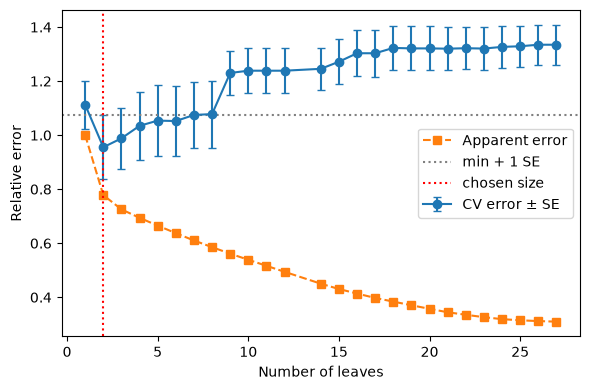

In [12]:
# CV diagnostic plot (the equivalent of mvpart's size-vs-error plot)
fig, ax = plt.subplots(figsize=(6, 4))
order = np.argsort(n_leaves)
ax.errorbar(n_leaves[order], cv_rel[order], yerr=cv_se[order], fmt="o-", capsize=3, label="CV error ± SE")
ax.plot(n_leaves[order], apparent[order], "s--", label="Apparent error")
ax.axhline(threshold, color="grey", ls=":", label=f"min + {SE_MULT:g} SE")
ax.axvline(n_leaves[i_pick], color="red", ls=":", label="chosen size")
ax.set_xlabel("Number of leaves"); ax.set_ylabel("Relative error")
ax.legend(); fig.tight_layout(); fig.savefig(OUT_DIR / "cv_error_vs_size.png", dpi=200)

## 8. Fit the final tree and summarise
Reports apparent R² and cross-validated R² (use the CV value as the honest one), the split rules, predictor contributions, which samples fall in which leaf, and mean community profiles per leaf (saved to `OUT_DIR`).

In [13]:
tree = make_tree(cps[i_pick] * root_impurity).fit(Xv, Yt)
leaf = tree.apply(Xv)                                  # leaf (node) id for each sample
pred = tree.predict(Xv)
R2_apparent = 1 - ((Yt - pred) ** 2).sum() / SS_total
R2_cv = 1 - cv_rel[i_pick]                             # report this one as the honest value
print(f"\nFinal tree: {tree.get_n_leaves()} leaves | apparent R2 = {R2_apparent:.3f} | CV R2 = {R2_cv:.3f}")

def print_rules(fitted, names):
    """Print split thresholds and sample counts (export_text would print 132 values per node)."""
    t = fitted.tree_
    def rec(node, depth):
        pad = "|   " * depth
        if t.children_left[node] == -1:
            print(f"{pad}-> leaf {node}: n = {t.n_node_samples[node]}")
            return
        f, thr = names[t.feature[node]], t.threshold[node]
        print(f"{pad}{f} <= {thr:.3f}   (node {node}, n = {t.n_node_samples[node]})")
        rec(t.children_left[node], depth + 1)
        print(f"{pad}{f} >  {thr:.3f}")
        rec(t.children_right[node], depth + 1)
    rec(0, 0)

print("\nSplit rules:")
print_rules(tree, list(X.columns))

# Share of the total SS explained by each predictor (impurity-based importance)
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Predictor contribution to explained SS:")
display(imp[imp > 0].round(3).to_frame("share of explained SS"))

# Which samples fall in which leaf, plus the mean community profile of each leaf
# (in the transformed space the tree was fit on)
assign = pd.DataFrame({"sample": sample_labels, SITE_COL: groups, DATE_COL: bio[DATE_COL], "leaf": leaf})
assign.to_csv(OUT_DIR / "leaf_assignments.csv", index=False)
profiles = pd.DataFrame(Yt, columns=taxa_cols).groupby(leaf).mean()
profiles.insert(0, "n_samples", pd.Series(leaf).value_counts().sort_index())
profiles.to_csv(OUT_DIR / "leaf_mean_profiles.csv")
print("\nSamples per leaf, by station:")
display(pd.crosstab(assign["leaf"], assign[SITE_COL]))


Final tree: 2 leaves | apparent R2 = 0.222 | CV R2 = 0.045

Split rules:
CaCO3 <= 8.315   (node 0, n = 70)
|   -> leaf 1: n = 31
CaCO3 >  8.315
|   -> leaf 2: n = 39
Predictor contribution to explained SS:


,share of explained SS
CaCO3,1.0



Samples per leaf, by station:


Site,PB02,PB03,PB04,PB05,PB06,PB07,PB08
leaf,,,,,,,
1,10,10,10,1,0,0,0
2,0,0,0,9,10,10,10


**Final tree plot**


Outputs written to /Users/Emily/Library/CloudStorage/Box-Box/Classes/OCS 7001 Scientific Computing (Fall 2026)/mrt_output


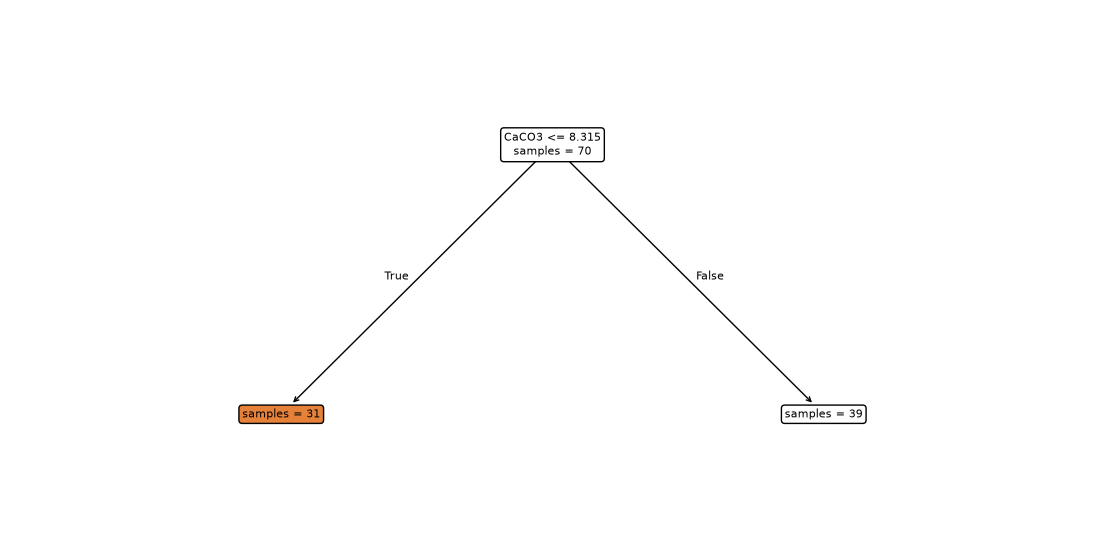

In [14]:
fig, ax = plt.subplots(figsize=(14, 7))
boxes = plot_tree(tree, feature_names=list(X.columns), filled=True, impurity=False,
                  rounded=True, ax=ax, fontsize=8)
for b in boxes:   # drop the per-taxon "value = [...]" block (one line per taxon); keep split rule and n
    keep = [l for l in b.get_text().split("\n") if not l.strip().startswith(("value", "["))]
    b.set_text("\n".join(keep))
fig.savefig(OUT_DIR / "final_tree.png", dpi=200, bbox_inches="tight")
print(f"\nOutputs written to {OUT_DIR.resolve()}")